# Attention maps, gradients, and perturbations

Companion to the consolidated manuscript, Appendix A.

**Claim.** Attention weights, input gradients and finite replacement effects measure different dependencies of the same output.

**Method.** One hand-specified attention sublayer processes 16 synthetic image patches and a summary token. Its parameters are not trained; the parameter-randomization comparison uses seed 2026, matching the September source. The shared implementation checks gradients by central finite differences.

**Result.** The generated panels compare attention, local sensitivity and two occlusion baselines. A value-only intervention leaves attention unchanged while changing the output.

**Limit.** This is a teaching example, not a trained clinical Transformer, patient result, human attentional mechanism or training-label randomization test.

Run after installing the repository dependencies. The first cell regenerates figures and numerical results under paper/figures.


{
  "score": 1.5860540455289716,
  "marker_replaced_score": 1.0577920825420555,
  "marker_effect": 0.5282619629869161,
  "value_changed_score": -1.45716519550483,
  "randomized_score": 0.4560228998268976,
  "gradient_check_max_abs_error": 4.711525197764743e-10
}


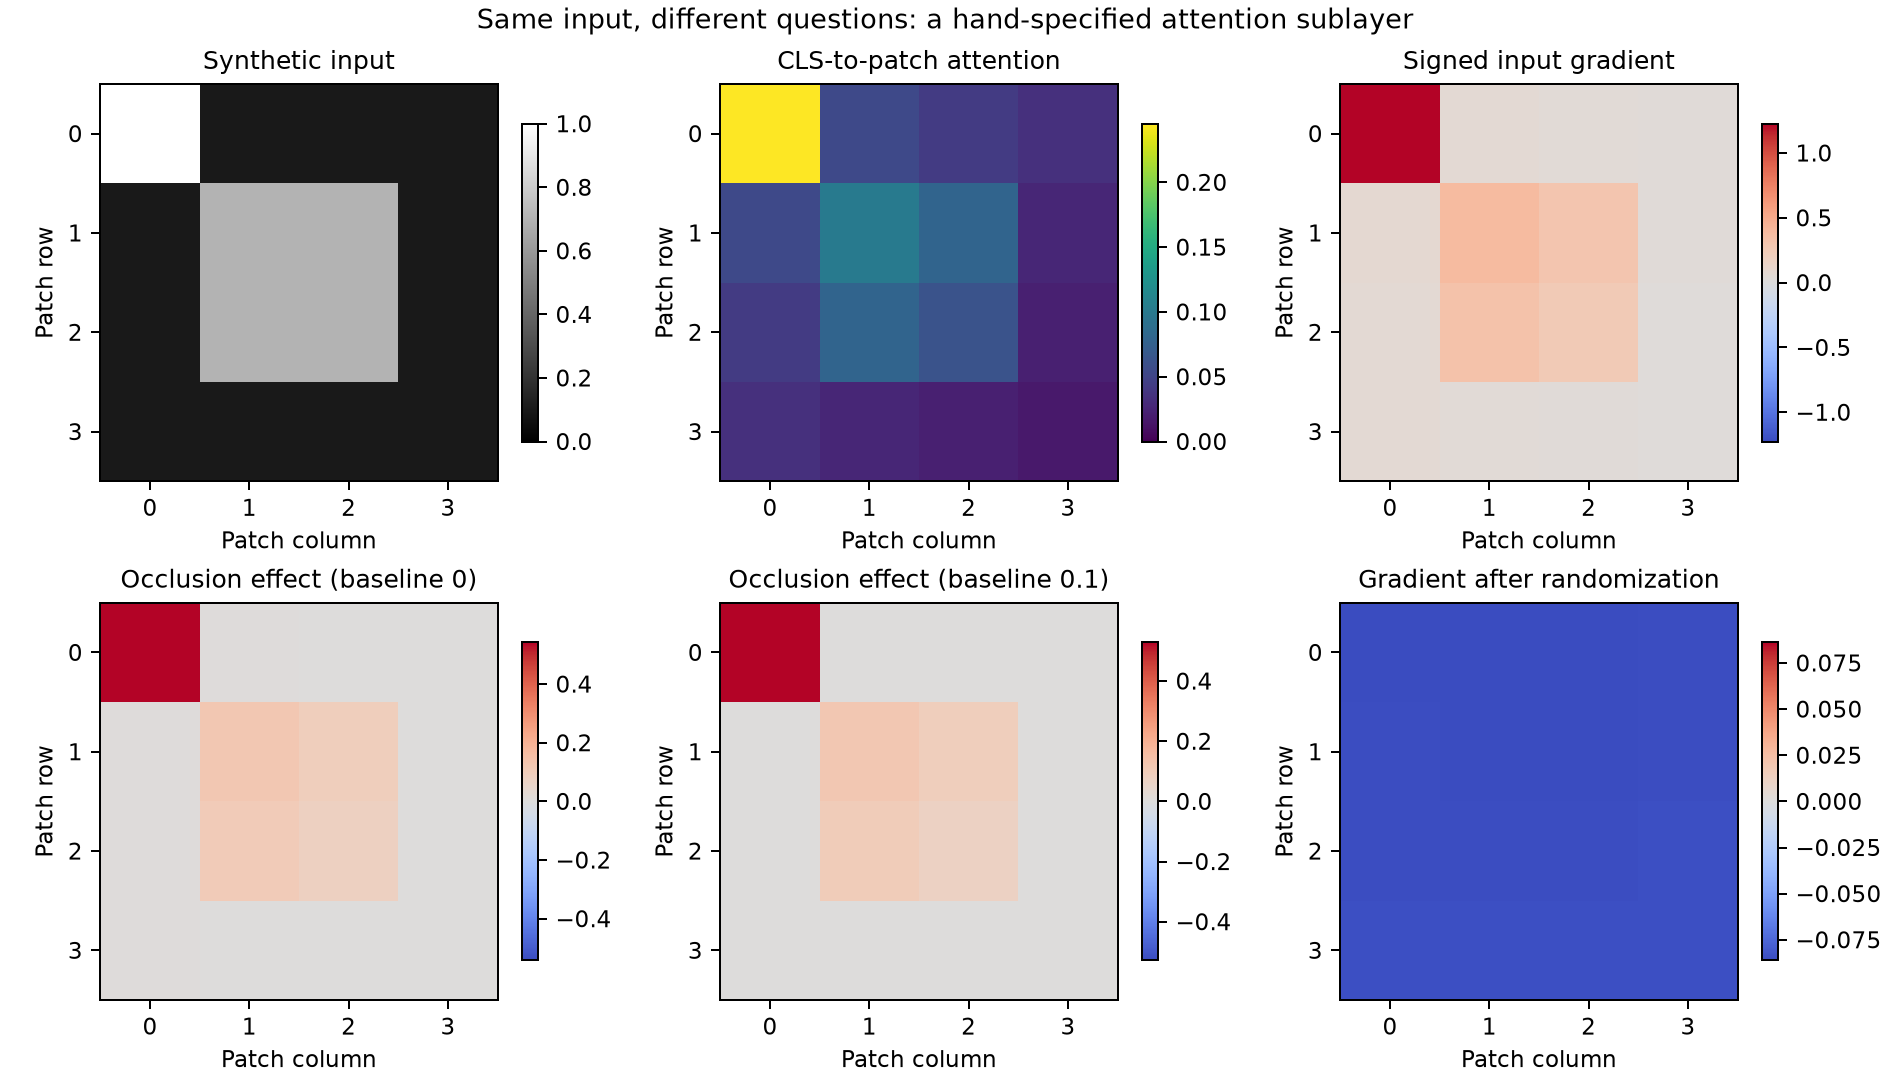

In [1]:
from pathlib import Path
import sys
repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
sys.path.insert(0, str(repo / 'code' / 'src'))
from brainsmodels.attention_maps import main
main()
from IPython.display import Image, display
display(Image(filename=str(repo / 'paper' / 'figures' / 'attention_maps.png')))


## Try a controlled intervention

Change only the occlusion baseline from 0 to 0.1 in the call below. Predict which outputs should change before rerunning it. The forward score, attention and gradient should stay fixed; replacement effects may change. Avoid comparing colours across panels: each uses its own numerical scale.


In [2]:
import numpy as np
from brainsmodels.attention_maps import tokens, parameters, maps
patches = np.full((4, 4), 0.1)
patches[1:3, 1:3] = 0.7
patches[0, 0] = 1.0
X, params = tokens(patches), parameters()
score, attention, gradient, effects = maps(X, params, baseline=0.0)
other = maps(X, params, baseline=0.1)
assert score == other[0]
assert np.array_equal(attention, other[1])
assert np.array_equal(gradient, other[2])
assert not np.array_equal(effects, other[3])
print("Score:", score)
print("Maximum replacement-effect change:", np.max(np.abs(effects - other[3])))


Score: 1.5860540455289716
Maximum replacement-effect change: 0.013532767369214271
